## Import

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[_v] = "1"   # single-threaded so parallel jobs do not fight over cores

import json, os, time, pickle, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             log_loss, average_precision_score, mean_squared_error, mean_absolute_error, r2_score)
warnings.filterwarnings("ignore")
torch.set_num_threads(1)

## Setup

In [2]:
SEED = 42
np.random.seed(SEED)
assert os.path.exists("weights_V5_0/regression_pytorch_test_metrics.json"), "pytorch twin must run first (epochs come from it)"
ORA = {r["model"]: r for r in json.load(open("weights_V5_0/regression_pytorch_test_metrics.json"))["models"]}
os.makedirs("weights_V5_0", exist_ok=True)
DELTA, HH = 0.5, 64
NAME = "NAM (log1p + Huber) | ReLU | "

In [3]:
df = pd.read_csv("marketing_campaign.csv", sep="\t")
df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
ref_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (ref_date - df["Dt_Customer"]).dt.days
df["Age"] = 2014 - df["Year_Birth"]
df = df[~df["Year_Birth"].isin([1893, 1899, 1900])].copy()
df = df[df["Income"] != 666666].copy()  # drop $666,666 income outlier (same treatment as Year_Birth sentinels)
df["Marital_Status"] = df["Marital_Status"].replace({"Absurd": "Single", "YOLO": "Single", "Alone": "Single"})
df = df.dropna(subset=["Income"]).copy()  # 2213 rows (target must not be imputed)
print("cleaned:", df.shape, "| Income max:", f"{df['Income'].max():,.0f}", "| median:", f"{df['Income'].median():,.0f}")
REG_FEATURES = ["NumCatalogPurchases","MntMeatProducts","MntWines","NumWebVisitsMonth","MntSweetProducts",
    "MntFruits","NumWebPurchases","MntGoldProds","NumStorePurchases","MntFishProducts","Kidhome","Age","NumDealsPurchases"]
X_full = df[REG_FEATURES].values; y_raw = df["Income"].values.astype(float)
print(f"features: {len(REG_FEATURES)} dims (all numeric)")

cleaned: (2212, 28) | Income max: 162,397 | median: 51,371
features: 13 dims (all numeric)


## Feature Interaction

In [4]:
# Feature interaction hand-off (Feature Interaction section of regression.ipynb):
# Teenhome interacts with most spend features but is not in the 13-feature model set.
EXTRA = ["Teenhome"]
COLS_ALL = REG_FEATURES + EXTRA
X_all = df[COLS_ALL].values.astype(float)

def top_pairs(csv_path, cols, k, must_include=None, exclude=None):
    """Top-k significant (q < 0.05) pairs by effect size where both features are in `cols`."""
    t = pd.read_csv(csv_path)
    t = t[(t.q < 0.05) & t.A.isin(cols) & t.B.isin(cols)]
    if must_include is not None:
        t = t[t.A.eq(must_include) | t.B.eq(must_include)]
    if exclude is not None:
        t = t[~(t.A.eq(exclude) | t.B.eq(exclude))]
    t = t.sort_values("effect", ascending=False)
    return list(zip(t.A.head(k), t.B.head(k)))

PAIRS_13 = top_pairs("results/interaction_reg.csv", REG_FEATURES, 4)
PAIRS_T = top_pairs("results/interaction_reg.csv", COLS_ALL, 5, must_include="Teenhome")
print("pairs (13 features):", PAIRS_13); print("pairs (with Teenhome):", PAIRS_T)
SETS = {
    "13 features":                    dict(cols=REG_FEATURES, pairs=[]),
    "+ Teenhome (14)":                dict(cols=COLS_ALL, pairs=[]),
    "13 features + 4 pair nets":      dict(cols=REG_FEATURES, pairs=PAIRS_13),
    "+ Teenhome + 5 Teenhome pairs":  dict(cols=COLS_ALL, pairs=PAIRS_T),
}

def prep_split(tr_idx, te_idx, set_name):
    cols = SETS[set_name]["cols"]
    ci = [COLS_ALL.index(c) for c in cols]
    sc = StandardScaler().fit(X_all[tr_idx][:, ci])
    return sc.transform(X_all[tr_idx][:, ci]), sc.transform(X_all[te_idx][:, ci]), y_raw[tr_idx], y_raw[te_idx]

idx_all = np.arange(len(y_raw))
tr_idx, te_idx = train_test_split(idx_all, test_size=0.20, random_state=SEED)
for s_ in SETS:
    a_, b_, _, _ = prep_split(tr_idx, te_idx, s_)
    print(f"{s_:32s} train {a_.shape} test {b_.shape}")

pairs (13 features): [('MntGoldProds', 'NumWebPurchases'), ('MntFruits', 'NumDealsPurchases'), ('MntFishProducts', 'NumWebPurchases'), ('NumWebPurchases', 'NumCatalogPurchases')]
pairs (with Teenhome): [('Teenhome', 'NumCatalogPurchases'), ('Teenhome', 'NumWebVisitsMonth'), ('Teenhome', 'MntWines'), ('Teenhome', 'MntMeatProducts'), ('Teenhome', 'NumStorePurchases')]
13 features                      train (1769, 13) test (443, 13)
+ Teenhome (14)                  train (1769, 14) test (443, 14)
13 features + 4 pair nets        train (1769, 13) test (443, 13)
+ Teenhome + 5 Teenhome pairs    train (1769, 14) test (443, 14)


## Dataloader

In [5]:
def use_set(sname):
    """Select one feature set: scaled arrays (float64), log-z target, and the pair-subnet index list."""
    global Xtr, Xte, ytr_raw, yte_raw, ytr_z, MU, SIG, NF, PAIR_IDX, NP
    Xa, Xb, ya, yb = prep_split(tr_idx, te_idx, sname)
    Xtr, Xte, ytr_raw, yte_raw = Xa.astype(np.float64), Xb.astype(np.float64), ya, yb
    ysc = StandardScaler().fit(np.log1p(ya).reshape(-1, 1))
    ytr_z = ysc.transform(np.log1p(ya).reshape(-1, 1)).ravel().astype(np.float64)
    MU, SIG = float(ysc.mean_[0]), float(ysc.scale_[0])
    cols = SETS[sname]["cols"]
    NF = len(cols); PAIR_IDX = [(cols.index(a), cols.index(b)) for a, b in SETS[sname]["pairs"]]; NP = len(PAIR_IDX)
use_set(next(iter(SETS)))
print(f"train {Xtr.shape} test {Xte.shape} | y_log scaler: mean {MU:.4f} scale {SIG:.4f}")

train (1769, 13) test (443, 13) | y_log scaler: mean 10.7459 scale 0.5066


## Model

In [6]:
def init_params():
    """1D subnets: W1 (F,1,H), W2 (F,H,1). NA2M pair subnets: pW1 (P,2,H), pW2 (P,H,1). ReLU only."""
    global P_
    P_ = {}
    P_["W1"] = np.random.randn(NF, 1, HH) * np.sqrt(2.0 / 1.0); P_["b1"] = np.zeros((NF, HH))
    P_["W2"] = np.random.randn(NF, HH, 1) * np.sqrt(2.0 / HH); P_["b2"] = np.zeros((NF, 1))
    P_["b0"] = np.zeros(1)
    if NP:
        P_["pW1"] = np.random.randn(NP, 2, HH) * np.sqrt(2.0 / 2.0); P_["pb1"] = np.zeros((NP, HH))
        P_["pW2"] = np.random.randn(NP, HH, 1) * np.sqrt(2.0 / HH); P_["pb2"] = np.zeros((NP, 1))
    return P_
for s_ in SETS:
    use_set(s_); print(f"{s_:32s} scratch parameters: {sum(a.size for a in init_params().values())}")

13 features                      scratch parameters: 2510
+ Teenhome (14)                  scratch parameters: 2703
13 features + 4 pair nets        scratch parameters: 3538
+ Teenhome + 5 Teenhome pairs    scratch parameters: 3988


In [7]:
def fwd(Xb):
    B = Xb.shape[0]
    Z1 = Xb[:, :, None] * P_["W1"][:, 0, :][None, :, :] + P_["b1"][None, :, :]  # (B,F,H)
    A1 = np.maximum(Z1, 0)
    Fj = np.einsum("bfh,fh->bf", A1, P_["W2"][:, :, 0]) + P_["b2"].ravel()        # (B,F)
    pred = Fj.sum(1, keepdims=True) + P_["b0"]
    cache = [Xb, Z1, A1, None, None, None]
    if NP:
        XP = np.stack([Xb[:, [i, j]] for i, j in PAIR_IDX], axis=1)                # (B,P,2)
        PZ = np.einsum("bpk,pkh->bph", XP, P_["pW1"]) + P_["pb1"][None]            # (B,P,H)
        PA = np.maximum(PZ, 0)
        Fp = np.einsum("bph,ph->bp", PA, P_["pW2"][:, :, 0]) + P_["pb2"].ravel()   # (B,P)
        pred = pred + Fp.sum(1, keepdims=True)
        cache[3:] = [XP, PZ, PA]
    return pred, tuple(cache)

In [8]:
def huber(pred, y):
    e = (pred.ravel() - y.ravel()); B = len(e)
    q = np.abs(e) <= DELTA  # tie -> quadratic branch (torch parity)
    loss = np.where(q, 0.5 * e ** 2, DELTA * (np.abs(e) - 0.5 * DELTA)).mean()
    dp = np.where(q, e, DELTA * np.sign(e)).reshape(-1, 1) / B
    return float(loss), dp

In [9]:
def bwd(dp, cache, G):
    Xb, Z1, A1, XP, PZ, PA = cache; B = Xb.shape[0]
    G["b0"] += dp.sum(0)
    dF = np.broadcast_to(dp, (B, NF))
    G["b2"] += dF.sum(0).reshape(NF, 1)
    G["W2"] += np.einsum("bfh,bf->fh", A1, dF)[:, :, None]
    dA = dF[:, :, None] * P_["W2"][None, :, :, 0]
    dZ = dA * (Z1 > 0)
    G["b1"] += dZ.sum(0)
    G["W1"] += np.einsum("bf,bfh->fh", Xb, dZ)[:, None, :]
    if NP:
        dFp = np.broadcast_to(dp, (B, NP))
        G["pb2"] += dFp.sum(0).reshape(NP, 1)
        G["pW2"] += np.einsum("bph,bp->ph", PA, dFp)[:, :, None]
        dPZ = dFp[:, :, None] * P_["pW2"][None, :, :, 0] * (PZ > 0)
        G["pb1"] += dPZ.sum(0)
        G["pW1"] += np.einsum("bpk,bph->pkh", XP, dPZ)

## Sanity Check

In [10]:
for sname in SETS:
    use_set(sname); init_params()
    Xc, yc = Xtr[:2], ytr_z[:2]
    p0, c0 = fwd(Xc); _, dp0 = huber(p0, yc)
    G0 = {k: np.zeros_like(a) for k, a in P_.items()}; bwd(dp0, c0, G0)
    checks = [("W2", (0, 0, 0)), ("W1", (1, 0, 3)), ("b1", (4, 2)), ("b2", (2, 0))]
    if NP: checks += [("pW1", (0, 1, 3)), ("pW1", (NP - 1, 0, 5)), ("pb1", (0, 2)), ("pW2", (0, 4, 0)), ("pb2", (NP - 1, 0))]
    for key, idx in checks:
        e = 1e-5; old = P_[key][idx]
        P_[key][idx] = old + e; lp = huber(fwd(Xc)[0], yc)[0]
        P_[key][idx] = old - e; lm = huber(fwd(Xc)[0], yc)[0]
        P_[key][idx] = old
        num, ana = (lp - lm) / (2 * e), G0[key][idx]
        err = abs(num - ana) / (abs(num) + abs(ana) + 1e-6)   # floor: an inactive ReLU unit has an exactly-zero gradient
        print(f"{sname:32s} check {key}{list(idx)}: numeric {num:.6e} analytic {ana:.6e} | relerr {err:.2e}")
        assert err < 1e-4, "backward pass does not match the numeric slope"

13 features                      check W2[0, 0, 0]: numeric -5.197365e-01 analytic -5.197365e-01 | relerr 4.34e-11
13 features                      check W1[1, 0, 3]: numeric 3.482470e-02 analytic 3.482470e-02 | relerr 8.11e-10
13 features                      check b1[4, 2]: numeric 0.000000e+00 analytic 0.000000e+00 | relerr 0.00e+00
13 features                      check b2[2, 0]: numeric -5.000000e-01 analytic -5.000000e-01 | relerr 2.55e-11
+ Teenhome (14)                  check W2[0, 0, 0]: numeric 5.739568e-02 analytic 5.739568e-02 | relerr 3.74e-11
+ Teenhome (14)                  check W1[1, 0, 3]: numeric 5.072447e-03 analytic 5.072447e-03 | relerr 2.79e-10
+ Teenhome (14)                  check b1[4, 2]: numeric 1.110223e-11 analytic 0.000000e+00 | relerr 1.11e-05
+ Teenhome (14)                  check b2[2, 0]: numeric 2.220446e-11 analytic 0.000000e+00 | relerr 2.22e-05
13 features + 4 pair nets        check W2[0, 0, 0]: numeric -4.323358e-01 analytic -4.323358e-01 | reler

## Training

In [11]:
LR0, WD, B1, B2, EP = 1e-3, 1e-4, 0.9, 0.999, 1e-8
def to_dollar(z): return np.expm1(np.clip(np.asarray(z).ravel() * SIG + MU, 0.0, 15.0))   # MU, SIG belong to the active feature set
def train_huber():
    tot = 0.0
    for i in range(0, len(Xtr), 256):
        p, _ = fwd(Xtr[i:i+256]); l, _ = huber(p, ytr_z[i:i+256]); tot += l * (min(i + 256, len(Xtr)) - i)
    return tot / len(Xtr)

runs = {}
for vname in SETS:
    use_set(vname)
    np.random.seed(SEED + 7)
    init_params()
    E = int(ORA[NAME + vname]["epochs"])                  # epoch count chosen by the pytorch twin's inner validation
    M = {k: np.zeros_like(a) for k, a in P_.items()}; V = {k: np.zeros_like(a) for k, a in P_.items()}
    N = len(Xtr); step = 0; hist = []
    for epoch in range(1, E + 1):
        lr = 0.5 * LR0 * (1 + np.cos(np.pi * (epoch - 1) / 100))
        perm = np.random.permutation(N)
        for i in range(0, N, 64):
            idx = perm[i:i+64]
            pred, cache = fwd(Xtr[idx]); _, dp = huber(pred, ytr_z[idx])
            G = {k: np.zeros_like(a) for k, a in P_.items()}
            bwd(dp, cache, G); step += 1
            for k in P_:
                g = G[k] + WD * P_[k]
                M[k] = B1 * M[k] + (1 - B1) * g; V[k] = B2 * V[k] + (1 - B2) * (g ** 2)
                mh = M[k] / (1 - B1 ** step); vh = V[k] / (1 - B2 ** step)
                P_[k] -= lr * (mh / (np.sqrt(vh) + EP))
        hist.append(train_huber())
    runs[vname] = dict(P={k: a.copy() for k, a in P_.items()}, E=E, hist=hist)
    print(f"{vname:32s} trained {E} epochs | final train Huber {hist[-1]:.4f}")

13 features                      trained 95 epochs | final train Huber 0.0838


+ Teenhome (14)                  trained 99 epochs | final train Huber 0.0742


13 features + 4 pair nets        trained 95 epochs | final train Huber 0.0834


+ Teenhome + 5 Teenhome pairs    trained 95 epochs | final train Huber 0.0683


## Evaluation

In [12]:
results, scores, history = [], {}, {}
for vname in SETS:
    use_set(vname)
    P_ = runs[vname]["P"]
    d = to_dollar(fwd(Xte)[0]); scores[vname] = d
    mse = float(mean_squared_error(yte_raw, d))
    results.append(dict(model=NAME + vname, tier="extracurricular", selection="inner validation",
        r2=round(float(r2_score(yte_raw, d)), 4), rmse=round(float(np.sqrt(mse)), 1), mae=round(float(mean_absolute_error(yte_raw, d)), 1),
        mse=round(mse, 1), epochs=runs[vname]["E"], n_params=int(sum(a.size for a in P_.values()))))
    history[vname] = runs[vname]["hist"]
table = pd.DataFrame(results)
print(table.drop(columns=["tier", "selection"]).to_string(index=False))
json.dump({"n_test": int(len(yte_raw)), "seed": SEED, "models": results}, open("weights_V5_0/regression_scratch_test_metrics.json", "w"), indent=2)
np.savez("weights_V5_0/regression_scratch_test_scores.npz", y_true=yte_raw, **scores)
np.savez("weights_V5_0/regression_scratch.npz", **{f"{v}|{k}": a for v, r in runs.items() for k, a in r["P"].items()})
pd.DataFrame({v: pd.Series(h) for v, h in history.items()}).rename_axis("epoch").to_csv("weights_V5_0/regression_scratch_history.csv")

                                                     model     r2    rmse    mae         mse  epochs  n_params
                  NAM (log1p + Huber) | ReLU | 13 features 0.7212 11507.7 7176.0 132426146.9      95      2510
              NAM (log1p + Huber) | ReLU | + Teenhome (14) 0.7511 10873.7 6748.9 118237477.3      99      2703
    NAM (log1p + Huber) | ReLU | 13 features + 4 pair nets 0.7122 11691.9 7407.1 136699684.6      95      3538
NAM (log1p + Huber) | ReLU | + Teenhome + 5 Teenhome pairs 0.7686 10484.3 6355.7 109919957.0      95      3988


## Parity Check

In [13]:
import warnings
import torch
import torch.nn as nn
warnings.filterwarnings("ignore")
torch.set_num_threads(1)
device = torch.device("cpu")

class SubNet(nn.Module):
    """Linear(n_in -> hid) - ReLU - Linear(hid -> 1). n_in = 1 for a feature, 2 for a feature pair."""
    def __init__(self, n_in=1, hid=64):
        super().__init__()
        self.fc1 = nn.Linear(n_in, hid); self.fc2 = nn.Linear(hid, 1); self.relu = nn.ReLU()
        nn.init.kaiming_normal_(self.fc1.weight, nonlinearity="relu"); nn.init.zeros_(self.fc1.bias)
        nn.init.kaiming_normal_(self.fc2.weight, nonlinearity="relu"); nn.init.zeros_(self.fc2.bias)
    def forward(self, x): return self.fc2(self.relu(self.fc1(x)))

class NAM(nn.Module):
    """Sum of per-feature subnets (+ optional 2D subnets for chosen feature pairs, i.e. NA2M) + bias."""
    def __init__(self, n_feat, pair_idx=(), hid=64):
        super().__init__()
        self.pair_idx = [tuple(p) for p in pair_idx]
        self.subs = nn.ModuleList([SubNet(1, hid) for _ in range(n_feat)])
        self.pairs = nn.ModuleList([SubNet(2, hid) for _ in self.pair_idx])
        self.b0 = nn.Parameter(torch.zeros(1))
    def forward(self, x):
        out = sum(sub(x[:, j:j + 1]) for j, sub in enumerate(self.subs)) + self.b0
        for (i, j), net in zip(self.pair_idx, self.pairs):
            out = out + net(x[:, [i, j]])
        return out

DELTA = 0.5
def make_model(v, seed, n_feat=None):
    torch.manual_seed(seed)
    cols, pairs = SETS[v]["cols"], SETS[v]["pairs"]
    idx = [(cols.index(a), cols.index(b)) for a, b in pairs]
    return NAM(n_feat=len(cols), pair_idx=idx).to(device)

def load_into_torch(m, Pn):
    with torch.no_grad():
        for f, s_ in enumerate(m.subs):
            s_.fc1.weight.copy_(torch.tensor(Pn["W1"][f, 0, :]).view(-1, 1)); s_.fc1.bias.copy_(torch.tensor(Pn["b1"][f]))
            s_.fc2.weight.copy_(torch.tensor(Pn["W2"][f, :, 0]).view(1, -1)); s_.fc2.bias.copy_(torch.tensor(Pn["b2"][f]))
        for p, s_ in enumerate(m.pairs):
            s_.fc1.weight.copy_(torch.tensor(Pn["pW1"][p].T)); s_.fc1.bias.copy_(torch.tensor(Pn["pb1"][p]))
            s_.fc2.weight.copy_(torch.tensor(Pn["pW2"][p, :, 0]).view(1, -1)); s_.fc2.bias.copy_(torch.tensor(Pn["pb2"][p]))
        m.b0.copy_(torch.tensor(Pn["b0"]))

for vname in SETS:
    use_set(vname); P_ = runs[vname]["P"]
    xb, yb_ = Xtr[:64], ytr_z[:64]
    m = make_model(vname, 0).double().eval(); load_into_torch(m, P_)
    pt = m(torch.tensor(xb)); loss_t = nn.HuberLoss(delta=DELTA)(pt, torch.tensor(yb_).view(-1, 1)); loss_t.backward()
    ps, cache = fwd(xb); loss_s, dp = huber(ps, yb_)
    G = {k: np.zeros_like(a) for k, a in P_.items()}; bwd(dp, cache, G)
    d_out = float(np.abs(pt.detach().numpy() - ps).max()); d_loss = abs(float(loss_t) - loss_s)
    g_t = {"W1": np.stack([s.fc1.weight.grad.numpy().ravel() for s in m.subs])[:, None, :], "b1": np.stack([s.fc1.bias.grad.numpy() for s in m.subs]),
           "W2": np.stack([s.fc2.weight.grad.numpy().ravel() for s in m.subs])[:, :, None], "b2": np.stack([s.fc2.bias.grad.numpy() for s in m.subs]), "b0": m.b0.grad.numpy()}
    if NP:
        g_t.update({"pW1": np.stack([s.fc1.weight.grad.numpy().T for s in m.pairs]), "pb1": np.stack([s.fc1.bias.grad.numpy() for s in m.pairs]),
                    "pW2": np.stack([s.fc2.weight.grad.numpy().ravel() for s in m.pairs])[:, :, None], "pb2": np.stack([s.fc2.bias.grad.numpy() for s in m.pairs])})
    d_grad = max(float(np.abs(g_t[k] - G[k]).max() / (np.abs(g_t[k]).max() + 1e-12)) for k in G)
    print(f"{vname:32s} | pair nets {NP} | max|dpred| {d_out:.2e} | dloss {d_loss:.2e} | max rel grad diff {d_grad:.2e}")
    assert d_out < 1e-8 and d_loss < 1e-8 and d_grad < 1e-6, "scratch and PyTorch disagree on identical weights"
    assert sum(a.size for a in P_.values()) == ORA[NAME + vname]["n_params"], "parameter count differs from the pytorch twin"
print("scratch forward and backward match PyTorch on identical weights; parameter counts match")
for r in results:
    o_ = ORA[r["model"]]
    print(f"{r['model']:56s} dR2 {abs(r['r2'] - o_['r2']):.4f} (different random init: informational, the exact check is the parity above)")


13 features                      | pair nets 0 | max|dpred| 2.33e-15 | dloss 5.55e-17 | max rel grad diff 3.55e-15
+ Teenhome (14)                  | pair nets 0 | max|dpred| 2.44e-15 | dloss 1.39e-17 | max rel grad diff 7.16e-15
13 features + 4 pair nets        | pair nets 4 | max|dpred| 2.22e-15 | dloss 2.78e-17 | max rel grad diff 9.37e-15
+ Teenhome + 5 Teenhome pairs    | pair nets 5 | max|dpred| 1.22e-14 | dloss 8.33e-17 | max rel grad diff 5.09e-15
scratch forward and backward match PyTorch on identical weights; parameter counts match
NAM (log1p + Huber) | ReLU | 13 features                 dR2 0.0018 (different random init: informational, the exact check is the parity above)
NAM (log1p + Huber) | ReLU | + Teenhome (14)             dR2 0.0099 (different random init: informational, the exact check is the parity above)
NAM (log1p + Huber) | ReLU | 13 features + 4 pair nets   dR2 0.0068 (different random init: informational, the exact check is the parity above)
NAM (log1p + Huber) 

## Loss Curve

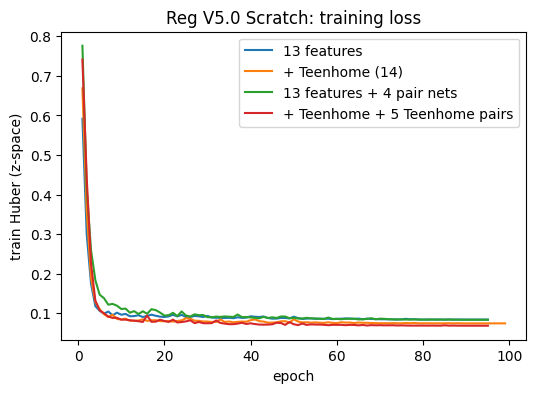

In [14]:
import matplotlib.pyplot as plt
os.makedirs("media", exist_ok=True)
plt.figure(figsize=(6, 4))
for v, h in history.items(): plt.plot(range(1, len(h) + 1), h, label=v)
plt.xlabel("epoch"); plt.ylabel("train Huber (z-space)"); plt.legend(); plt.title("Reg V5.0 Scratch: training loss")
plt.savefig("media/loss_reg_V5_0.png", dpi=150); plt.show()